<a href="https://colab.research.google.com/github/Stephane1902/Titanic/blob/main/Brief_Titanic_groupe_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

En tant que Data Scientist junior au sein d’un cabinet de conseil en data, vous êtes missionné par un musée maritime. Celui-ci prépare une exposition interactive sur le naufrage du Titanic et souhaite répondre à une question : « Quels facteurs ont réellement influencé les chances de survie des passagers ? »

Le musée vous transmet un fichier CSV issu de ses archives (dataset Titanic, Kaggle). Ce fichier n’est pas exploitable directement :

environ 20 % des âges sont manquants ;

la colonne Cabin est vide à plus de 75 % ;

certaines informations utiles sont cachées dans du texte (le titre Mr, Mrs, Miss ou Master dans le nom des passagers) ;

les variables catégorielles (Sex, Embarked) doivent être encodées ;

certaines colonnes n’apportent aucune information prédictive (PassengerId, Ticket).

Votre mission se déroule en 4 étapes :

Analyse exploratoire (EDA) : comprendre la structure des données, les distributions, les corrélations et les valeurs aberrantes, puis formuler des hypothèses (par exemple : « les femmes et les passagers de 1re classe ont davantage survécu »).

Nettoyage et transformation : traiter les valeurs manquantes en justifiant chaque choix, encoder les variables, créer de nouvelles variables pertinentes (feature engineering : titre, taille de la famille, voyage seul…),

Modélisation : entraîner et comparer au moins 3 modèles de classification (par exemple régression logistique, Random Forest, XGBoost),

Compétences visées :

C34 : assurer le nettoyage, la transformation et la réduction de la dimensionnalité des datasets

C39 : effectuer l’analyse exploratoire des donnéesE

In [ ]:
import pandas as pd
import zipfile

In [ ]:
df_titanic = pd.read_csv('dataset-titanic-kaggle.csv')

### **EDA : Analyse exploratoire**

In [ ]:
df_titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
print(df_titanic.shape)

(891, 12)


In [ ]:
df_titanic.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [ ]:
df_titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
# on regarde les statistiques descriptives du dataset df_titanic
df_titanic.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Il ne semble pas avoir de valeurs aberrantes dans ce dataset.

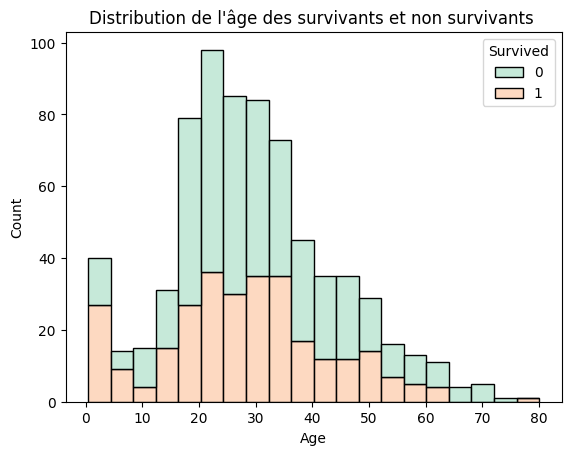

In [ ]:
# histogramme de la distribution des âges, avec une distinction entre survivants et non-survivants
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(
    data= df_titanic,
    x="Age",
    hue="Survived",
    multiple = "stack",
    palette = 'Pastel2'
)
plt.title("Distribution de l'âge des survivants et non survivants ")
plt.show()

Les chances de survie dont plus élevées pour les jeunes enfants 0 à 5 ans, et les adulte de 20 à 35 ans. A partir de 60 ans la chance de survie est quasi nulle.

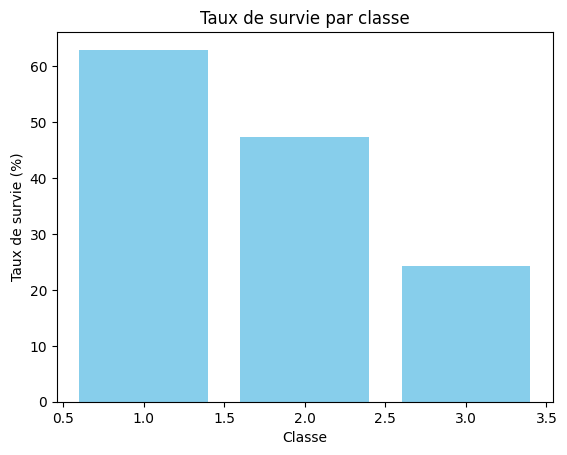

In [ ]:
# graphique en barres montrant le taux de survie par classe de passager

tx_survie_classe1 = df_titanic.groupby(['Pclass'])['Survived'].mean() * 100

plt.bar(x=tx_survie_classe1.index,
        height=tx_survie_classe1.values,
        color='skyblue')

plt.title("Taux de survie par classe")
plt.xlabel("Classe")
plt.ylabel("Taux de survie (%)")
plt.show()


In [ ]:
tx_survie_classe1

,Survived
Pclass,
1,62.962963
2,47.282609
3,24.236253


La classe joue sur la chance de survie des passagers. Mieux ils sont classés plus ils ont de chance de survies.

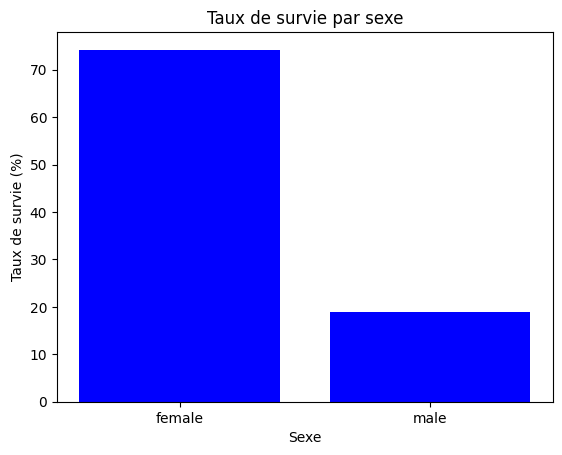

In [ ]:
# graphique en barres montrant le taux de survie par sexe de passager

tx_survie_classe = df_titanic.groupby(['Sex'])['Survived'].mean() * 100

plt.bar(x=tx_survie_classe.index,
        height=tx_survie_classe.values,
        color='blue')

plt.title("Taux de survie par sexe")
plt.xlabel("Sexe")
plt.ylabel("Taux de survie (%)")
plt.show()


Les femmes ont plus de chances de survies que d'hommes

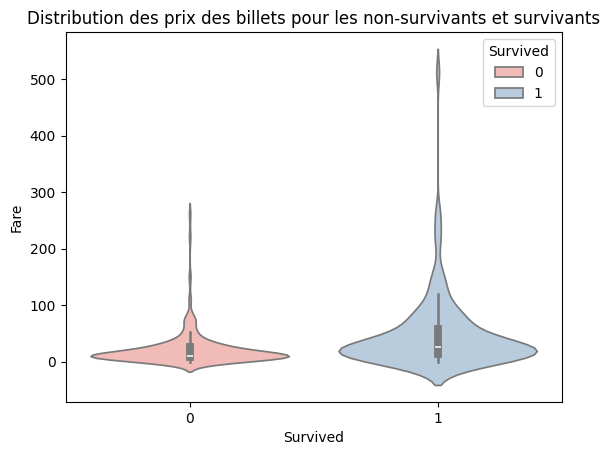

In [ ]:
# graphique en violon pour comparer la distribution des tarifs (Fare) entre les survivants et les non-survivants
sns.violinplot(data = df_titanic, x = 'Survived', y='Fare', hue = 'Survived', palette = 'Pastel1')
plt.title("Distribution des prix des billets pour les non-survivants et survivants")
plt.show()

Le prix du billet influence la chance de survie, parmis les survivants il y a plus de personnes ayant acheté des billets chers.

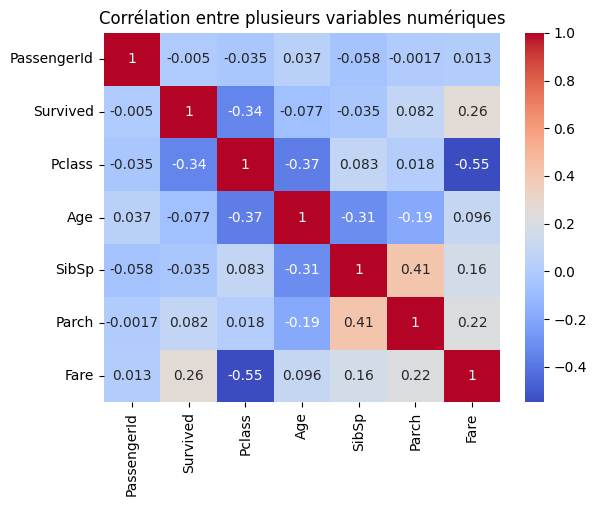

In [ ]:
# heatmap de corrélation pour toutes les variables numériques

corr = df_titanic[['PassengerId','Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].corr()

sns.heatmap(corr, annot = True, cmap='coolwarm')
plt.title("Corrélation entre plusieurs variables numériques")
plt.show()

### **Nettoyage de données**

In [ ]:
df_titanic.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
df_titanic["Embarked"].value_counts()

,count
Embarked,
S,644
C,168
Q,77


Supprimer valeurs manquantes "Embarked" ?
Remplacer age par median ou mean ?
Remplacer valeurs manquantes "Cabin" par "Unknown" ?

In [ ]:
# On supprime le colonnes non pertinentes pour entraîner notre modèle de machine learning
df_titanic = df_titanic.drop(columns=["PassengerId", "Ticket"], axis = 0)

In [ ]:
df_titanic

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,NaN,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C85,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,NaN,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,C123,S
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...
886,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,13.0000,NaN,S
887,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,30.0000,B42,S
888,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,23.4500,NaN,S
889,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,30.0000,C148,C


In [ ]:

df_titanic['Age'] = df_titanic['Age'].fillna((df_titanic['Age'].mean()))

df_titanic.isna().sum()

,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,687
Embarked,2


On remplace les valeurs manquantes d'age par la moyenne car il y a beaucoup de valeurs manquantes qu'on ne veut pas supprimer pour garder un maximum de données, on remplace par la moyenne car la moyenne et la médiane sont quasi semblables

In [ ]:
df_titanic['Cabin'].value_counts()

,count
Cabin,
G6,4
C23 C25 C27,4
B96 B98,4
F2,3
D,3
...,...
E17,1
A24,1
C50,1


In [ ]:
df_titanic['Cabin'] =  df_titanic['Cabin'].fillna('Unknown')

On remplace les valeurs manquantes de cabines par "Inconnu" car on ne peut pas deviner pour un autant grand nombre le numéro de cabine des passagers

In [ ]:
df_titanic['Embarked'] = df_titanic['Embarked'].fillna((df_titanic['Embarked'].mode()[0]))

On a juste deux valeurs manquantes pour Embarked donc on peut remplacer par le mode pour remplacer par la valeur la plus représentée

In [ ]:
# on vérifie que l'on a bien traité toutes les valeurs manquantes
df_titanic.isna().sum()

,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,0
Embarked,0


In [ ]:
# création d'une nouvelle colonne pour la taille de la famille (feature engineering)

df_titanic['Total_Family'] = df_titanic['SibSp'] + df_titanic['Parch'] + 1

df_titanic.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,Total_Family
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,Unknown,S,2
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C85,C,2
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,Unknown,S,1
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,C123,S,2
4,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,Unknown,S,1


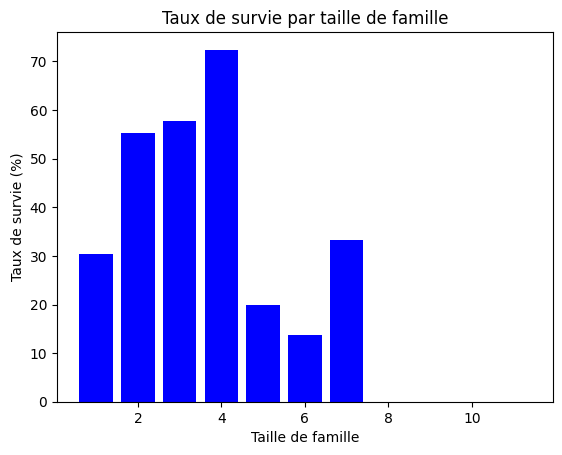

In [ ]:

tx_survie_classe = df_titanic.groupby(['Total_Family'])['Survived'].mean() * 100

plt.bar(x=tx_survie_classe.index,
        height=tx_survie_classe.values,
        color='blue')

plt.title("Taux de survie par taille de famille")
plt.xlabel("Taille de famille")
plt.ylabel("Taux de survie (%)")
plt.show()


In [ ]:
# création d'une nouvelle colonne pour extraire le titre de la personne(feature engineering)

df_titanic['Title'] = df_titanic['Name'].str.extract(
    r',\s*([^.]*)\.',
    expand=False
)

In [ ]:
# création d'une nouvelle colonne à l'aide d'une fonction pour définir si la personne est un enfant ou non (age < 18)

def is_child(row):
    if row < 18:
        row1=1
    else:
        row1=0
    return row1
df_titanic["is_child"] = df_titanic["Age"].apply(is_child)

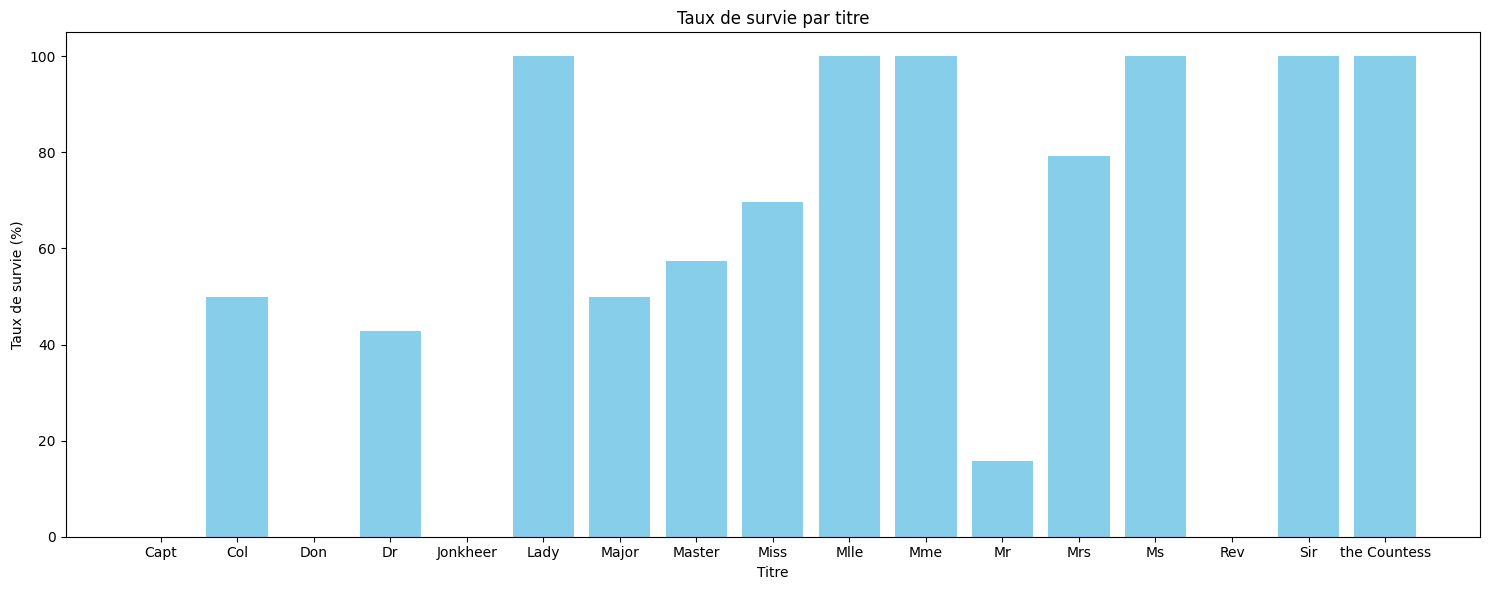

In [ ]:
# graphique en barres montrant le taux de survie par classe de passager

plt.subplots(figsize = (15, 6))
tx_survie_classe1 = df_titanic.groupby(['Title'])['Survived'].mean() * 100

plt.bar(x=tx_survie_classe1.index,
        height=tx_survie_classe1.values,
        color='skyblue')

plt.title("Taux de survie par titre")
plt.xlabel("Titre")
plt.ylabel("Taux de survie (%)")
plt.tight_layout()
plt.show()


In [ ]:
df_titanic.head(15)

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,Total_Family,Title,is_child
0,0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,7.2500,Unknown,S,2,Mr,0
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000000,1,0,71.2833,C85,C,2,Mrs,0
2,1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,7.9250,Unknown,S,1,Miss,0
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000000,1,0,53.1000,C123,S,2,Mrs,0
4,0,3,"Allen, Mr. William Henry",male,35.000000,0,0,8.0500,Unknown,S,1,Mr,0
5,0,3,"Moran, Mr. James",male,29.699118,0,0,8.4583,Unknown,Q,1,Mr,0
6,0,1,"McCarthy, Mr. Timothy J",male,54.000000,0,0,51.8625,E46,S,1,Mr,0
7,0,3,"Palsson, Master. Gosta Leonard",male,2.000000,3,1,21.0750,Unknown,S,5,Master,1
8,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.000000,0,2,11.1333,Unknown,S,3,Mrs,0
9,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.000000,1,0,30.0708,Unknown,C,2,Mrs,1


In [ ]:
df_titanic['Title'].value_counts()

,count
Title,
Mr,517
Miss,182
Mrs,125
Master,40
Dr,7
Rev,6
Col,2
Mlle,2
Major,2


In [ ]:
# encodage des variable catégorielles

df_encoded = pd.get_dummies(df_titanic, columns = ['Sex', 'Embarked', 'Title'], drop_first = True, dtype = int)
df_encoded = df_encoded.drop(['Name','Cabin'], axis = 1)
df_encoded.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Total_Family,is_child,Sex_male,Embarked_Q,...,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Title_the Countess
0,0,3,22.0,1,0,7.2500,2,0,1,0,...,0,0,0,0,1,0,0,0,0,0
1,1,1,38.0,1,0,71.2833,2,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,1,3,26.0,0,0,7.9250,1,0,0,0,...,0,1,0,0,0,0,0,0,0,0
3,1,1,35.0,1,0,53.1000,2,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,0,3,35.0,0,0,8.0500,1,0,1,0,...,0,0,0,0,1,0,0,0,0,0


In [ ]:
display(df_encoded.columns)

Index(['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Total_Family',
       'is_child', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Title_Col',
       'Title_Don', 'Title_Dr', 'Title_Jonkheer', 'Title_Lady', 'Title_Major',
       'Title_Master', 'Title_Miss', 'Title_Mlle', 'Title_Mme', 'Title_Mr',
       'Title_Mrs', 'Title_Ms', 'Title_Rev', 'Title_Sir',
       'Title_the Countess'],
      dtype='object')

**### Modélisation**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

In [ ]:
# définition des cibles et target
X = df_encoded.drop(['Survived'], axis = 1) #features

y = df_encoded['Survived'] #cible

In [ ]:

# split train/test

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42)

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[['Age', 'SibSp','Parch', 'Fare', 'Total_Family']] = scaler.fit_transform(X_train[['Age', 'SibSp','Parch', 'Fare', 'Total_Family']])

X_test_scaled[['Age', 'SibSp','Parch', 'Fare', 'Total_Family']] = scaler.transform(X_test[['Age', 'SibSp','Parch', 'Fare', 'Total_Family']])

modeles = {'Regression Logistique' : LogisticRegression(),
           'K Neighbors Classifier' : KNeighborsClassifier(n_neighbors=7),
           'Random Forest' : RandomForestClassifier(max_depth=4)}

conf_matrix = {}

for name, models in modeles.items():

    if name == 'Random Forest':
        models.fit(X_train, y_train)
        y_pred = models.predict(X_test)

        print(f"Score d'entraînement de {name} = {models.score(X_train, y_train):.2f}")
        print(f"Score de test de {name} = {models.score(X_test, y_test):.2f}")

    else:
        models.fit(X_train_scaled, y_train)
        y_pred = models.predict(X_test_scaled)

        print(f"Score d'entraînement de {name} = {models.score(X_train_scaled, y_train):.2f}")
        print(f"Score de test de {name} = {models.score(X_test_scaled, y_test):.2f}\n")

    # Confusion Matrix
    conf_matrix[name] = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_true=y_test, y_pred=y_pred),
                                                display_labels=["Died", "Survived"])

Score d'entraînement de Regression Logistique = 0.84
Score de test de Regression Logistique = 0.80

Score d'entraînement de K Neighbors Classifier = 0.85
Score de test de K Neighbors Classifier = 0.83

Score d'entraînement de Random Forest = 0.84
Score de test de Random Forest = 0.81


In [ ]:
resultats = pd.DataFrame({
    'Valeur réelle': y_test,
    'Prédiction': y_pred
})

print(resultats)

     Valeur réelle  Prédiction
709              1           0
439              0           0
840              0           0
720              1           1
39               1           1
..             ...         ...
433              0           0
773              0           0
25               1           0
84               1           1
10               1           1

[179 rows x 2 columns]


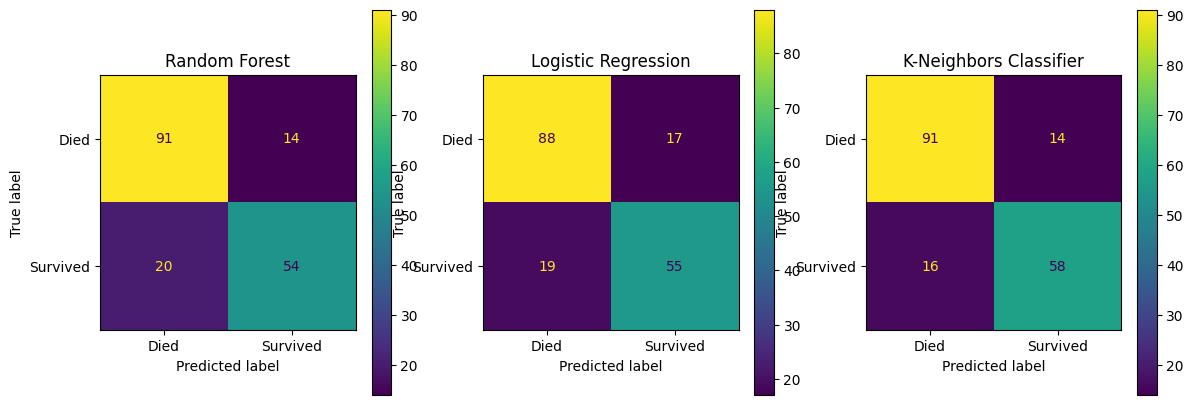

In [ ]:
# Plotting the confusion matrix for the 4 algorithms used

fig, (ax1, ax2,ax4) = plt.subplots(1, 3, figsize=(14, 5))
conf_matrix["Random Forest"].plot(ax=ax1)
ax1.title.set_text('Random Forest')

conf_matrix["Regression Logistique"].plot(ax=ax2)
ax2.title.set_text("Logistic Regression")

#conf_matrix["DecisionTree"].plot(ax=ax3)
#ax3.title.set_text( "Decision Tree")

conf_matrix["K Neighbors Classifier"].plot(ax=ax4)
ax4.title.set_text("K-Neighbors Classifier")